# 야후 파이낸스 주가 데이터 웹 스크래핑
- 야후 파이낸스 외 주식 데이터 웹 스크래핑할 수 있는 사이트들
    - google Finance: BS 파싱
    - alpha vantage: API 제공
    - finviz: BS 파싱
    - trading economics: BS 파싱 또는 API 

## SK 하이닉스 주가 데이터 웹 스크래핑
1. finance.yahoo.com 에서 SK hynix Inc. 종목 정보 확인 페이지 이동
2. 일별 시세 확인: Historical Data
3. 사용자 에이전트 값 확인
- 야후 삼성전자 페이지에서 f12 눌러서 개발자 도구 열고 Network 탭 클릭
- 새로고침해서 서버로 다시 요청 보내면 history 항목이 맨 위에 나타남
- history 눌러서 Requests Headers에서 User-Agent 값 & Accept 값 복사

In [35]:
import pandas as pd
import numpy as np

In [26]:
import requests
import urllib3
from bs4 import BeautifulSoup

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning) # SSL 검증 비활성화

stock_url = 'https://finance.yahoo.com/quote/000660.KS/history/'
# 헤더 값 설정
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/148.0.0.0 Safari/537.36',
    'accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7'
}

# 헤더를 담아 웹 페이지 요청
res = requests.get(stock_url, headers=headers, verify=False)
html = res.text # 응답에서 HTML 문서만 가져오기
print(html)

<!doctype html>
<html lang="en-US" theme="auto" data-color-theme-enabled="true" data-color-scheme="auto" class="desktop neo-green dock-upscale">
    <head>
        <meta charset="utf-8" />
        <meta name="oath:guce:consent-host" content="guce.yahoo.com" />
        <link rel="preconnect" href="//s.yimg.com" crossorigin="anonymous"><link rel="preconnect" href="//geo.yahoo.com"/><link rel="preconnect" href="//query1.finance.yahoo.com"/><link rel="preconnect" href="//consent.cmp.oath.com"/><link rel="preload" href="/__rapidworker-1.2.js" as="worker"/><link rel="preconnect" href="https://s.yimg.com/uc/finance/webcore/js/_staticFinProtobuf.4ac0aa7cd811394598dc.js"/><link rel="preconnect" href="https://cdn.jsdelivr.net/npm/protobufjs@7.1.2/dist/minimal/protobuf.min.js"/><script>window.finNeoPageStart = Date.now();</script><script>
    (function(){if(!window.YAHOO){window.YAHOO={}};window.YAHOO.context={"consent":{"allowContentPersonalization":true,"allowCrossDeviceMapping":true,"allowFirs

In [27]:
# res.text를 뷰티풀수프에 전달하여 html.parser로 파싱
soup = BeautifulSoup(html, 'html.parser')
print(soup)

<!DOCTYPE html>

<html class="desktop neo-green dock-upscale" data-color-scheme="auto" data-color-theme-enabled="true" lang="en-US" theme="auto">
<head>
<meta charset="utf-8"/>
<meta content="guce.yahoo.com" name="oath:guce:consent-host"/>
<link crossorigin="anonymous" href="//s.yimg.com" rel="preconnect"/><link href="//geo.yahoo.com" rel="preconnect"/><link href="//query1.finance.yahoo.com" rel="preconnect"/><link href="//consent.cmp.oath.com" rel="preconnect"/><link as="worker" href="/__rapidworker-1.2.js" rel="preload"/><link href="https://s.yimg.com/uc/finance/webcore/js/_staticFinProtobuf.4ac0aa7cd811394598dc.js" rel="preconnect"/><link href="https://cdn.jsdelivr.net/npm/protobufjs@7.1.2/dist/minimal/protobuf.min.js" rel="preconnect"/><script>window.finNeoPageStart = Date.now();</script><script>
    (function(){if(!window.YAHOO){window.YAHOO={}};window.YAHOO.context={"consent":{"allowContentPersonalization":true,"allowCrossDeviceMapping":true,"allowFirstPartyAds":true,"allowSellPe

- 개발자 도구 열기: 사이트 내에서 원하는 값에 마우스 오른쪽 클릭-[검사] 누르기

In [28]:
# 첫 번째 tr 태그의 클래스 이름 확인
first_tr = soup.find('tr')
first_class = first_tr.get('class')[0]
print(first_class)

yf-u4m6f0


In [29]:
# tr 요소에 있는 td 요소 중 class가 first_class인 경우 추출
print(soup.find_all("td", class_=first_class))

[<td class="yf-u4m6f0">Jun 22, 2026</td>, <td class="yf-u4m6f0">2,728,000.00</td>, <td class="yf-u4m6f0">2,945,000.00</td>, <td class="yf-u4m6f0">2,728,000.00</td>, <td class="yf-u4m6f0">2,887,000.00</td>, <td class="yf-u4m6f0">2,887,000.00</td>, <td class="yf-u4m6f0">3,806,093</td>, <td class="yf-u4m6f0">Jun 19, 2026</td>, <td class="yf-u4m6f0">2,824,000.00</td>, <td class="yf-u4m6f0">2,891,000.00</td>, <td class="yf-u4m6f0">2,688,000.00</td>, <td class="yf-u4m6f0">2,764,000.00</td>, <td class="yf-u4m6f0">2,764,000.00</td>, <td class="yf-u4m6f0">7,478,195</td>, <td class="yf-u4m6f0">Jun 18, 2026</td>, <td class="yf-u4m6f0">2,556,000.00</td>, <td class="yf-u4m6f0">2,738,000.00</td>, <td class="yf-u4m6f0">2,556,000.00</td>, <td class="yf-u4m6f0">2,685,000.00</td>, <td class="yf-u4m6f0">2,685,000.00</td>, <td class="yf-u4m6f0">5,808,765</td>, <td class="yf-u4m6f0">Jun 17, 2026</td>, <td class="yf-u4m6f0">2,335,000.00</td>, <td class="yf-u4m6f0">2,523,000.00</td>, <td class="yf-u4m6f0">2,

- 날짜, 종가 데이터만 추출

In [30]:
import pandas as pd

# 1. tr 태그 조건에 해당하는 모든 정보 검색
rows = soup.find_all('tr')

for i in range(1, len(rows)):      # 2. 첫 번째 tr 태그(헤더)를 제외하고 순회
    cells = rows[i].find_all('td') # 3. 각 tr 태그 내의 모든 td 태그를 찾기
    # 4. td 태그가 7개(날짜, 시가, 고가, 저가, 종가, 조정 종가, 거래량)인 경우만 처리
    # cf. 배당금 정보 포함된 행은 td 태그가 2개이므로 len(cells)=2, 따라서 처리 x
    if len(cells) == 7:
        date = pd.to_datetime(cells[0].text).strftime('%Y년 %m월 %d일')
        close_price = cells[4].text.replace('.00','원')
        print('날짜 :', date, "/ 종가 :", close_price)

날짜 : 2026년 06월 22일 / 종가 : 2,887,000원
날짜 : 2026년 06월 19일 / 종가 : 2,764,000원
날짜 : 2026년 06월 18일 / 종가 : 2,685,000원
날짜 : 2026년 06월 17일 / 종가 : 2,521,000원
날짜 : 2026년 06월 16일 / 종가 : 2,382,000원
날짜 : 2026년 06월 15일 / 종가 : 2,288,000원
날짜 : 2026년 06월 12일 / 종가 : 2,150,000원
날짜 : 2026년 06월 11일 / 종가 : 2,101,000원
날짜 : 2026년 06월 10일 / 종가 : 2,048,000원
날짜 : 2026년 06월 09일 / 종가 : 2,215,000원
날짜 : 2026년 06월 08일 / 종가 : 1,911,000원
날짜 : 2026년 06월 05일 / 종가 : 2,070,000원
날짜 : 2026년 06월 04일 / 종가 : 2,298,000원
날짜 : 2026년 06월 02일 / 종가 : 2,360,000원
날짜 : 2026년 06월 01일 / 종가 : 2,363,000원
날짜 : 2026년 05월 29일 / 종가 : 2,333,000원
날짜 : 2026년 05월 28일 / 종가 : 2,289,000원
날짜 : 2026년 05월 27일 / 종가 : 2,243,000원
날짜 : 2026년 05월 26일 / 종가 : 2,052,000원
날짜 : 2026년 05월 22일 / 종가 : 1,941,000원
날짜 : 2026년 05월 21일 / 종가 : 1,940,000원
날짜 : 2026년 05월 20일 / 종가 : 1,745,000원
날짜 : 2026년 05월 19일 / 종가 : 1,745,000원
날짜 : 2026년 05월 18일 / 종가 : 1,840,000원
날짜 : 2026년 05월 15일 / 종가 : 1,819,000원
날짜 : 2026년 05월 14일 / 종가 : 1,970,000원
날짜 : 2026년 05월 13일 / 종가 : 1,976,000원
날

- 날짜, 종가 변수 시각화

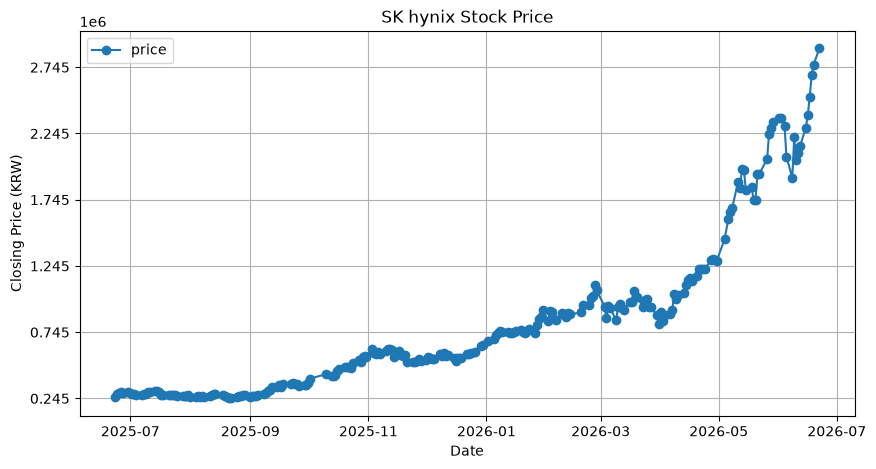

In [32]:
import matplotlib.pyplot as plt
# tr 태그 조건에 해당하는 모든 정보 검색
rows = soup.find_all("tr")

dates = []
prices = []

for i in range(1, len(rows)): 
    cells = rows[i].find_all('td')
    if len(cells) == 7:
        date = pd.to_datetime(cells[0].text, format='%b %d, %Y')
        close_price = cells[4].text.replace(',','').replace('.00','')
        dates.append(date) # 날짜를 dates 리스트에 추가
        prices.append(int(close_price)) # 종가를 정수로 변환하여 prices 리스트에 추가

stock_data = pd.DataFrame({'date': dates, 'price': prices})

# y축 눈금 간격 설정
min_price = min(stock_data['price'])
max_price = max(stock_data['price'])
y_ticks = range(min_price, max_price, 500000)

plt.figure(figsize=(10,5))
plt.plot(stock_data['date'], stock_data['price'], marker='o', label='price')
plt.xlabel('Date')
plt.ylabel('Closing Price (KRW)')
plt.title('SK hynix Stock Price')
plt.legend()
plt.grid(True)
plt.yticks(y_ticks)
plt.show()

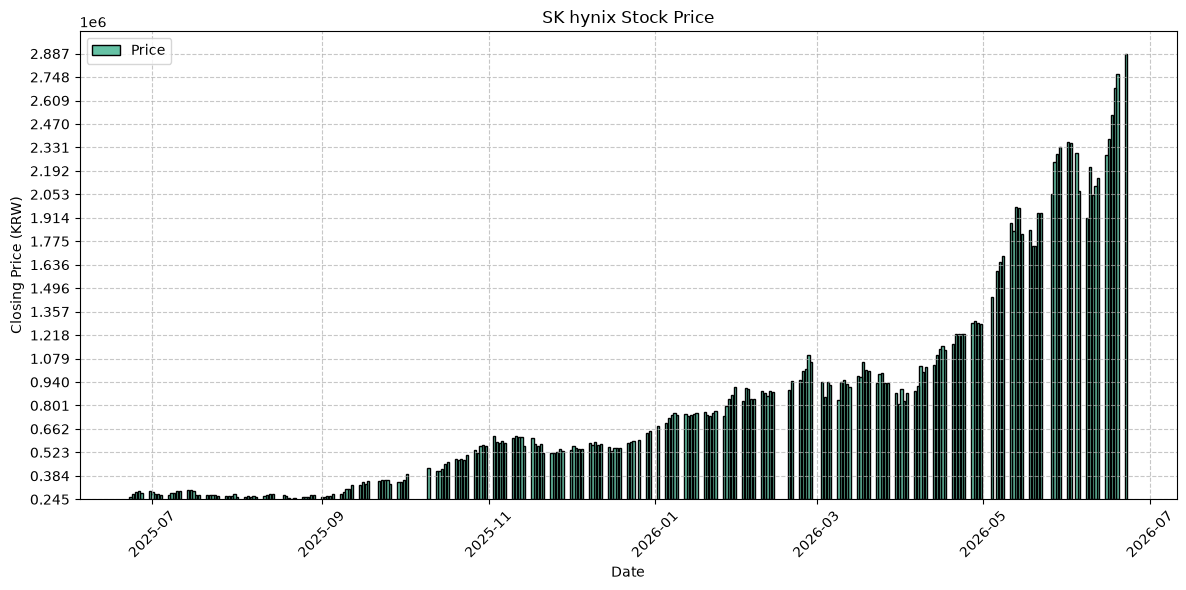

In [36]:
dates = []
prices = []

for i in range(1, len(rows)): 
    cells = rows[i].find_all('td')
    if len(cells) == 7:
        date = pd.to_datetime(cells[0].text, format='%b %d, %Y')
        close_price = cells[4].text.replace(',','').replace('.00','')
        dates.append(date) # 날짜를 dates 리스트에 추가
        prices.append(int(close_price)) # 종가를 정수로 변환하여 prices 리스트에 추가

stock_data = pd.DataFrame({'date': dates, 'price': prices})

# y축 틱 간격 설정
min_price = min(stock_data['price'])
max_price = max(stock_data['price'])
y_ticks = np.linspace(min_price, max_price, 20)

plt.figure(figsize=(12,6))
colors = plt.get_cmap('Set2')(np.linspace(0, 1, len(stock_data))) # 색상 맵을 사용하여 색상 지정

plt.bar(stock_data['date'], stock_data['price'] - min_price, bottom=min_price, color = colors[0], edgecolor='black')
plt.xlabel('Date')
plt.ylabel('Closing Price (KRW)')
plt.title('SK hynix Stock Price')
plt.legend(['Price'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.yticks(y_ticks)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 넷플릭스 데이터 분석
- 캐글 데이터셋 Netflix Movies and TV shows till 2025
    - https://www.kaggle.com/datasets/bhargavchirumamilla/netflix-movies-and-tv-shows-till-2025

In [42]:
netflix_mov = pd.read_csv('netflix_movies_detailed_up_to_2025.csv')
netflix_tvshows = pd.read_csv('netflix_tv_shows_detailed_up_to_2025.csv')

netflix = pd.concat([netflix_mov,netflix_tvshows], ignore_index=True)

netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000.0,752600867.0
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000.0,839030630.0
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000.0,954305868.0
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,NaN,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,7.600,260000000.0,592461732.0
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,NaN,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.044,13259,7.800,165000000.0,494879471.0


In [44]:
print(netflix['type'].value_counts())
print(netflix[['type','budget','revenue']].groupby('type').count())

type
Movie      16000
TV Show    16000
Name: count, dtype: int64
         budget  revenue
type                    
Movie     16000    16000
TV Show       0        0


In [45]:
# 열 이름 확인
list(netflix.columns)

['show_id',
 'type',
 'title',
 'director',
 'cast',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'genres',
 'language',
 'description',
 'popularity',
 'vote_count',
 'vote_average',
 'budget',
 'revenue']

In [46]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000 entries, 0 to 31999
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       32000 non-null  int64  
 1   type          32000 non-null  str    
 2   title         32000 non-null  str    
 3   director      20903 non-null  str    
 4   cast          30639 non-null  str    
 5   country       29737 non-null  str    
 6   date_added    32000 non-null  str    
 7   release_year  32000 non-null  int64  
 8   rating        32000 non-null  float64
 9   duration      16000 non-null  object 
 10  genres        30919 non-null  str    
 11  language      32000 non-null  str    
 12  description   28662 non-null  str    
 13  popularity    32000 non-null  float64
 14  vote_count    32000 non-null  int64  
 15  vote_average  32000 non-null  float64
 16  budget        16000 non-null  float64
 17  revenue       16000 non-null  float64
dtypes: float64(5), int64(3), object(1), s

## 결측치 처리하기
- 결측치 비율 5% 미만: 결측치 있는 행 삭제 권장
- 결측치 비율 5%~20% 미만: 결측치 대체 적절(평균, 중간값, 최빈값 또는 모델 기반 처리)
- 결측치 비율 20% 이상: 변수의 중요성, 분석 목적, 데이터 양 등 종합적으로 고려해 열 제거 여부 결정

In [47]:
# 결측치 비율 계산
for i in netflix.columns:
    missingValueRate = netflix[i].isna().sum() / len(netflix) * 100
    if missingValueRate > 0 :
        print("{} null rate: {}%".format(i, round(missingValueRate, 2)))

director null rate: 34.68%
cast null rate: 4.25%
country null rate: 7.07%
duration null rate: 50.0%
genres null rate: 3.38%
description null rate: 10.43%
budget null rate: 50.0%
revenue null rate: 50.0%


In [51]:
netflix[netflix['type'] == 'TV Show']['duration'].value_counts()

duration
1 Seasons    16000
Name: count, dtype: int64

In [53]:
netflix[netflix['revenue'].isnull() == False]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000.0,752600867.0
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000.0,839030630.0
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000.0,954305868.0
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,NaN,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,7.600,260000000.0,592461732.0
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,NaN,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.044,13259,7.800,165000000.0,494879471.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,1440286,Movie,Festival de Viña del Mar 2025: Ha*Ash,NaN,Ha*ash,Chile,2025-02-24,2025,0.000,NaN,Music,es,NaN,4.931,0,0.000,0.0,0.0
15996,1271724,Movie,Man and Woman,Vladimir Kott,"Anna Kotova, Stepan Devonin, Pavel Derevyanko,...",Russia,2025-03-13,2025,0.000,NaN,Drama,ru,Poignant stories about men and women who have ...,4.930,0,0.000,0.0,0.0
15997,1426364,Movie,Night of the Dead Sorority Babes,"Angel Nichole Bradford, Steve Hermann","Jessa Flux, Lynn Lowry, Angel Nichole Bradford...",NaN,2025-01-28,2025,1.000,NaN,Horror,en,Two villainous entities initiate gorgeous soro...,4.922,1,1.000,0.0,0.0
15998,1411248,Movie,A Dunces Burden,Daniel Kowal,"Riley G, Mitchel Corrado",NaN,2025-03-10,2025,0.000,NaN,NaN,en,A Dunces Burden,4.921,0,0.000,0.0,0.0


- 결측치 대체: director, country, cast, genres
- duration은 type='TV Shows'에만 있고, budget과 revenue는 type='Movie'에만 있음

In [57]:
# 결측치 대체
netflix['country'] = netflix['country'].fillna('No Data')
netflix['genres'] = netflix['genres'].fillna('No Data')
netflix['description'] = netflix['description'].fillna('No Data')

netflix['director'] = netflix['director'].replace(np.nan, 'No Data')
netflix['cast'] = netflix['cast'].replace(np.nan, 'No Data')

In [58]:
netflix.isna().sum()

show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added          0
release_year        0
rating              0
duration        16000
genres              0
language            0
description         0
popularity          0
vote_count          0
vote_average        0
budget          16000
revenue         16000
dtype: int64

## 시각화

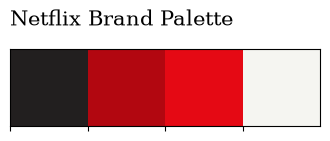

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 넷플릭스 브랜드 상징 색
sns.palplot(['#221f1f', '#b20710', '#e50914', '#f5f5f1']) # 색상 팔레트 시각화
plt.title('Netflix Brand Palette', loc='left', fontfamily='serif', fontsize=15, y=1.2)
plt.show()

- Squid Game 검색하기

In [65]:
# na = False: 값이 NA일 경우, False로 처리
# case = False: 대소문자를 구분하지 않고 검색
netflix['title'].str.contains('squid game', na=False, case=False)

0        False
1        False
2        False
3        False
4        False
         ...  
31995    False
31996    False
31997    False
31998    False
31999    False
Name: title, Length: 32000, dtype: bool

In [66]:
netflix[netflix['title'].str.contains('squid game', na=False, case=False)]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
13017,1214667,Movie,Making Squid Game: The Challenge,No Data,"Nicola Brown, Rikki Finlay, Tim Harcourt, Toni...",United Kingdom,2023-12-06,2023,6.900,NaN,Documentary,en,"Go behind the scenes and witness how the ""Squi...",119.003,56,6.900,0.0,0.0
14120,1408248,Movie,Squid Game: Fireplace,No Data,No Data,South Korea,2024-12-12,2024,6.000,NaN,No Data,xx,Come share a toast in the Front Man's lair — b...,118.966,41,6.000,0.0,0.0
15043,1412113,Movie,Squid Game: Making Season 2,No Data,"Hwang Dong-hyuk, Lee Jung-jae, Lee Byung-hun, ...",South Korea,2025-01-02,2025,8.500,NaN,Documentary,ko,"From set designs to character arcs, get exclus...",107.996,338,8.500,0.0,0.0
27001,93405,TV Show,Squid Game,No Data,"Lee Jung-jae, Lee Byung-hun, Yim Si-wan, Wi Ha...",South Korea,2021-09-17,2021,7.862,1 Seasons,"Action & Adventure, Mystery, Drama",ko,Hundreds of cash-strapped players accept a str...,836.570,15536,7.862,NaN,NaN
29035,204082,TV Show,Squid Game: The Challenge,No Data,"Jennie Kwan, Nick Martineau, Phill Cain, T.J. ...",United Kingdom,2023-11-22,2023,6.280,1 Seasons,Reality,en,"In this reality competition show inspired by ""...",137.739,480,6.280,NaN,NaN


- 장르 막대 그래프

In [69]:
# 장르별 등장 횟수 계산
genres = netflix['genres'].str.split(', ', expand=True).stack().value_counts()
genres

Drama                 14776
Comedy                 9110
Animation              4070
Thriller               3769
Action                 3239
Crime                  3203
Family                 3014
Mystery                2576
Romance                2571
Horror                 2425
Action & Adventure     1988
Sci-Fi & Fantasy       1958
Documentary            1827
Adventure              1768
Reality                1632
Science Fiction        1454
Fantasy                1450
No Data                1081
Kids                    835
History                 732
Talk                    655
Soap                    631
TV Movie                628
Music                   488
War                     420
War & Politics          323
Western                 154
News                    113
Unknown                 104
Name: count, dtype: int64

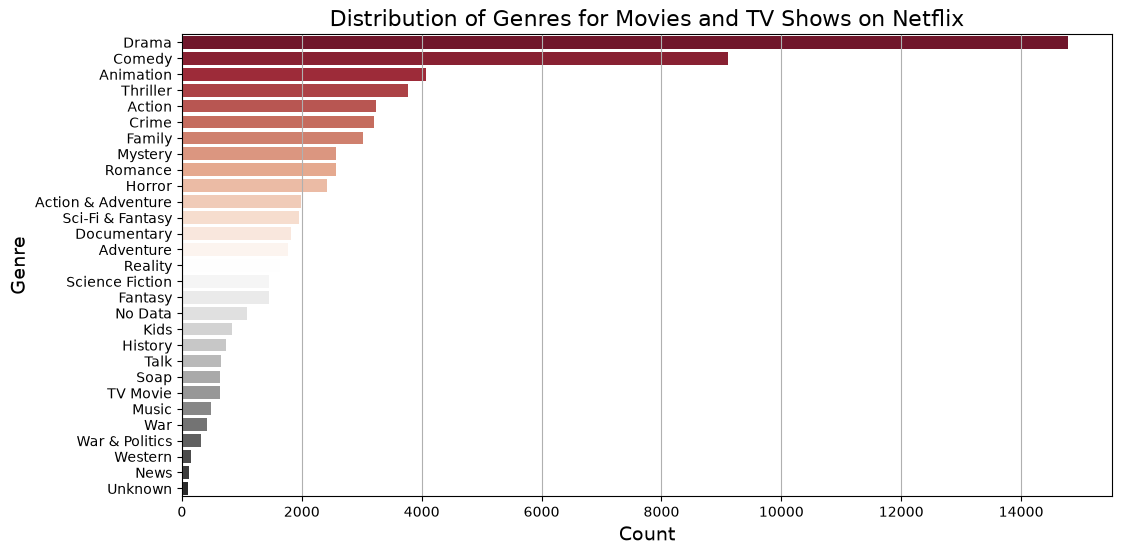

In [70]:
plt.figure(figsize=(12,6))

sns.barplot(x=genres.values, y=genres.index, hue=genres.index, palette='RdGy')
plt.title('Distribution of Genres for Movies and TV Shows on Netflix', fontsize=16)
plt.xlabel('Count', fontsize=14)
plt.ylabel('Genre', fontsize=14)
plt.grid(axis='x')
plt.show()

- 히트맵 그리기

- 워드 클라우드: description 열 이용

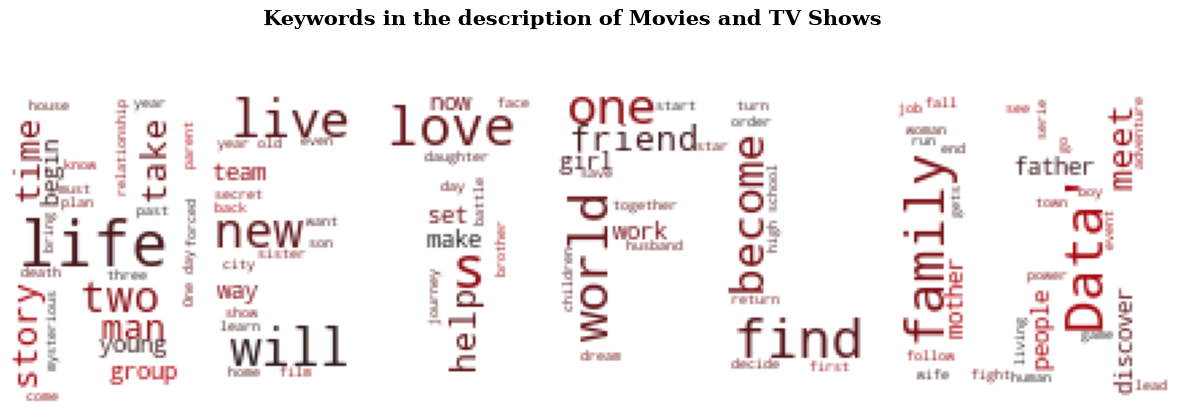

In [79]:
from wordcloud import WordCloud
from PIL import Image

plt.figure(figsize=(15,5))
text = str(list(netflix['description'])) # 1. description 열을 리스트 -> 문자열로 변환
# 2. 로고 이미지 열고 넘파이 배열로 변환
mask = np.array(Image.open('netflix_logo.jpg'))

# 3. 워드 클라우드 색상맵
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list('', ['#221f1f', '#b20710'])

# 4. 워드 클라우드 생성
wordcloud = WordCloud(background_color = 'white', width = 1000, height = 1000, max_words = 200, mask = mask, colormap=cmap).generate(text)

plt.suptitle('Keywords in the description of Movies and TV Shows', fontweight='bold', fontfamily='serif', fontsize=15)
plt.imshow(wordcloud) # 5. 워드 클라우드 표시
plt.axis('off')
plt.show()

- Korea 관련 데이터로 워드 클라우드 만들어보기

In [85]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. 필터링
korea_data = netflix[
    netflix['description'].str.contains('Korea', case=False, na=False) |
    netflix['title'].str.contains('Korea', case=False, na=False) |
    netflix['genres'].str.contains('Korea', case=False, na=False)
]

# 2. 텍스트 데이터 결합
text = ' '.join(korea_data['description'].dropna().tolist())

# 3. 피처 엔지니어링: CountVectorizer를 사용하여 단어 빈도수 추출
vectorizer = CountVectorizer(stop_words='english')
word_matrix = vectorizer.fit_transform([text])
word_freq = word_matrix.toarray().flatten()

words_df = pd.DataFrame({'word': vectorizer.get_feature_names_out(), 'freq': word_freq})

# 상위 10개 단어 출력
top_words_df = words_df.head(10)
print(top_words_df)

   word  freq
0    00     1
1   000     1
2    05     2
3    10    14
4   100     2
5   101     1
6   105     1
7  10th     1
8    11     6
9   112     1


C:\Users\926174\AppData\Local\Temp\ipykernel_15684\3056724468.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_words_df, x='freq', y='word', palette='viridis')


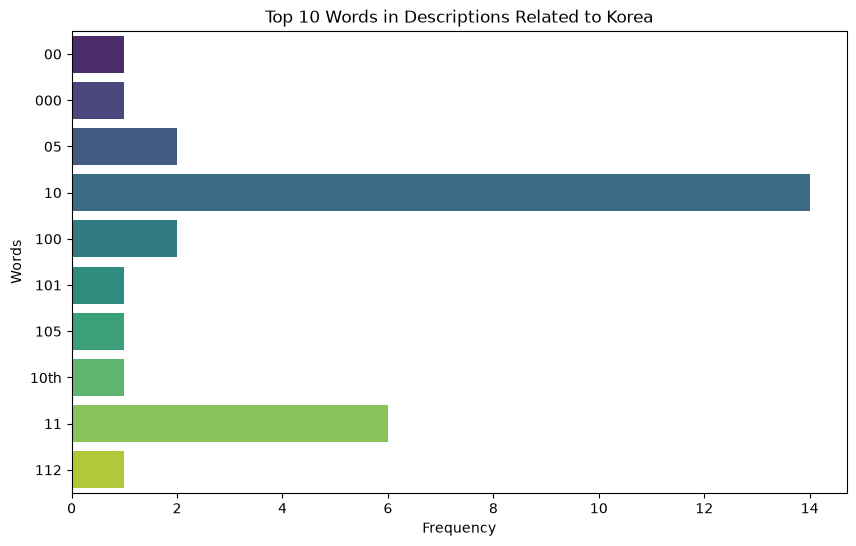

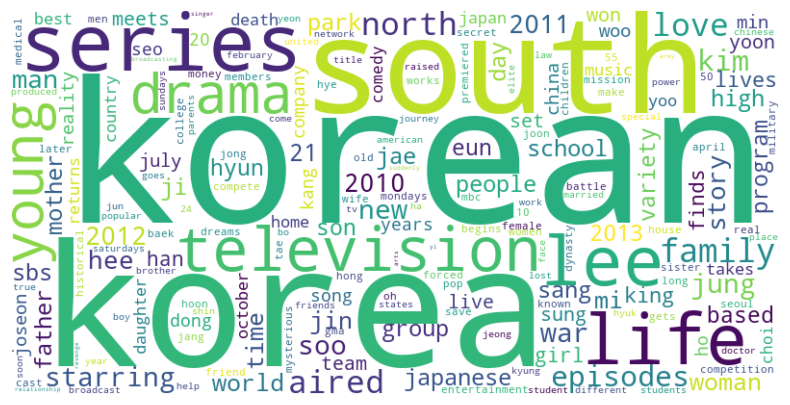

In [87]:
# 4. 시각화
plt.figure(figsize=(10,6))
sns.barplot(data=top_words_df, x='freq', y='word', palette='viridis')
plt.title('Top 10 Words in Descriptions Related to Korea')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

# 5. 워드클라우드 생성
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(dict(zip(words_df['word'], words_df['freq'])))

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## 피처 엔지니어링
1. 날짜/시간 피처: date_added -> 연도/월/요일/시즌 분리, 출시~등록 경과일
2. 멀티값 컬럼 인코딩: genres / country -> 멀티핫, cast / director -> 등장 빈도
3. duration 정제 및 파생 피처: "90 min" -> 숫자, 영화 길이 구간(short/medium/long), 시즌 수
4. 텍스트 피처(NLP): description -> TF-IDF / 감성 점수 / 키워드 추출
5. 인기도 파생 피처: vote_avg x log(vote_count) -> 가중 평점 / 인기 분위 구간
6. 그룹 집계 피처: 국가별 / 장르별 / 연도별 평균 평점 / 인기도, 감독 평균 성과